In [1]:
# needed when using ssh connection (?)
#%pip install tensorboard
#%pip install numpy
#%pip install torch
#%pip install matplotlib
#%pip install os
#%pip install scikit-learn
#%pip install seaborn
#pip install torch_geometric

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
from torch.utils.data import DataLoader, TensorDataset, Subset
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import r2_score
import seaborn as sns
import torch_geometric.nn as gnn
from torch_geometric.loader import DataLoader
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, global_mean_pool, global_max_pool
import copy

/home/astrouser/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/astrouser/.local/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
# TOGGLE/OPTIONS/HYPERPARAMETERS CELL
ssh_connected = 1 # change to 1 if connected to supercomputer

norm = 1 # change to 1 to normalise the fluxes
roll = 1 # change to 1 if wanting to roll the times/phases
noise_level = 0 # 0 for no noise, 1 for low noise level, 2 for high

period_toggle = 0 # 0 for period as input, 1 for period as predicted parameter

num_params = 8 + period_toggle # number of parameters model will predict (currently, 8 without period, 9 with)
n_scalars = 6 - period_toggle # number of scalar inputs to model. 4 are passbands flux averages, 1 is distance. the 6th is period, depending on period_toggle.
B = batch_size = 128 # number of systems processed before forward passing
lr = 1e-3
epochs = 500

early_stopping_toggle = 1 # 1: use early stopping
lr_scheduling_toggle = 1 # 1: use learning rate scheduling

# early stop criteria:
patience = 30 # how many epochs in a row with no improvement there needs to be before it stops early
delta = 0.000 # the minimum performance increase to count as an improvement

# learning rate scheduling criteria:
factor_lr = 0.5 # the amount to reduce the learning rate by each time it is told to
patience_lr = 10 # how many epochs without improvement to wait before reducing lr
min_lr = 5e-5 # the lowest the learning rate is allowed to go

In [4]:
cwd = os.getcwd()


if ssh_connected == 0:
    num_csvs = len(os.listdir("C:\\Users\\seanf\\OneDrive\\Documents\\Master's Files\\2nd Year\\Eclipsing Binaries\\Data\\ELISa lightcurve data"))
elif ssh_connected ==1:
    num_csvs = len(os.listdir("/home/astrouser/sean/Eclipsing Binaries/Data/ELISa lightcurve data"))


EB_labels = np.loadtxt(os.path.join(cwd, "Data", "ELISa lightcurve data", "_labels.csv"), delimiter=',', usecols=0)
labels = np.array([]) 
fluxes = np.array([])
phases = np.array([])
if period_toggle == 0:
    param_names = ["T_ratio", "T1", "q", "m1", "Omega1", "Omega2", "e", "i"]
elif period_toggle == 1:
    param_names = ["T_ratio", "T1", "q", "m1", "Omega1", "Omega2", "e", "i", "period"]
    
T1 = []     # set empty lists for parameters
T_ratio = []
q = []
m1 = []
Omega1 = []
Omega2 = []
e = []
i = []

dist = []
period = []

params_1000 = {} # create empty dictionary for parameter list contianing 1000 values

for name in param_names: # loop through parameter names, adding their values to their name in the dictionary
        params_1000[name] = np.loadtxt(
            os.path.join(cwd, "Data", "ELISa synthetic parameters", f"{name}.csv"),
            delimiter=',',
            skiprows=0
        )

#2026-10-15: removing period as a target parameter and inputting it into system indstead, also inputting distance. these are features you would know from an observation

periods = np.loadtxt(os.path.join(cwd, "Data", "ELISa synthetic parameters", "period.csv"),delimiter=',',skiprows=0)
distances = np.loadtxt(os.path.join(cwd, "Data", "ELISa synthetic parameters", "distance.csv"), delimiter=',', skiprows=0)

params = {} # create empty dict for correct number of param values

for name in param_names:
    # give empty dictionary correct keys
        params[name]=[]

fluxes_dict={} # initalise dict for use with multiple passbands fluxes
fluxes_final={'Generic.Bessell.B','Generic.Bessell.V','Generic.Bessell.R','Generic.Bessell.I'}
log_mean_B = log_mean_V = log_mean_R = log_mean_I = []

# looping through each light curve csv file, adding them all to one 2d array of dimensions (num_csvs x 100)
for i in range(0, 4*num_csvs): # using 4 * num_csvs as csvs (currently) go from 1-999, many are missing, so this ensures we get all files 
    data_path = os.path.join(cwd, "Data", "ELISa lightcurve data", f"{i} lightcurve.csv")
    if os.path.exists(data_path): # only loads file if a lightcurve with that number exists, otherwise skips to next iteration
        data = np.loadtxt(data_path, delimiter=',', skiprows=1)
        passbands = np.genfromtxt(data_path, delimiter=',', max_rows=1,dtype=str)[1:] # save all columns past 'time' as a list of strings


        phases = data[:, 0]

        label = EB_labels[i]  # get the corresponding label for the light curve. 
        labels = np.append(labels, label)


        if period_toggle == 0:
            period.append(np.log10(periods[i])) # log10-ing periods if they shall be input
        elif period_toggle == 1:
            period.append(periods[i])
        dist.append(np.log10(distances[i])) # select only the period and distance values with the correct indices to be used. 
        # log10-ing the distances becuase they can range from 20-200, so log keeps it more uniformly weighted in log space

        for name in param_names:
            if name == 'period': # log the periods, as they span a range that crosses orders of magnitude
                 params[name].append(np.log10(params_1000[name][i]))
            else:
            # insert only the parameters of the systems that are used into the new one - so that the system number for parameters matches with fluxes.
                params[name].append(params_1000[name][i])

        for j, band in enumerate(passbands): # enumerate returns both the item itself and its index
            if band not in fluxes_dict: # initialise the dictionary if it doesnt exist
                fluxes_dict[band] = data[:,j+1] # j+1 is needed as data[0] is the times, lightcurve data begins in column [1]
            else:
                fluxes_dict[band] = np.vstack((fluxes_dict[band], data[:,j+1])) # add the data to the array within the dictionary as a new row

    else:
        continue
print(fluxes_dict['Generic.Bessell.R'].shape)

log_mean_B = np.append(log_mean_B, np.log10(fluxes_dict['Generic.Bessell.B'].mean(axis=1))) # finds the mean flux of each passband to be used as an input
log_mean_V = np.append(log_mean_V, np.log10(fluxes_dict['Generic.Bessell.V'].mean(axis=1)))
log_mean_R = np.append(log_mean_R, np.log10(fluxes_dict['Generic.Bessell.R'].mean(axis=1)))
log_mean_I = np.append(log_mean_I, np.log10(fluxes_dict['Generic.Bessell.I'].mean(axis=1)))

(12644, 100)


In [5]:
print(params.keys())
dist_array=np.array(dist)
print(np.max(dist_array),np.min(dist_array))

print(len(periods))
print(len(distances))
print(len(dist))
print(len(period))

dict_keys(['T_ratio', 'T1', 'q', 'm1', 'Omega1', 'Omega2', 'e', 'i'])
2.301009764822739 1.3012959242334172
30000
30000
12644
12644


In [6]:
# creating phase offset parameter, intended to model the synthetic data more as realistic data, and to be predicted as a parameter in itself
print(fluxes_dict['Generic.Bessell.B'].shape)

system_length = fluxes_dict['Generic.Bessell.B'].shape[1] # how any data points are in each system

# at the moment, each phases_array is a 2d array, with 1000 rows (one for each system), each with 100 data points. 
# these data points are always 0.00 to 0.99, increasing by 0.01, for a totla of 100 data points.
# the goal of offsetting the phases is to make the data more like realistic observations,
# where the eclipse minimum does not always occur at exactly the same phase, as is happening here.

# the goal: add an offset to the phases. however, the range of phases should still be 0-0.99

# NOTE: rolling must occur during training, randomly per epoch
# otherwise the model will just learn the shapes and exact locations of the curves, instead of figuring out the phase shift and parameters
# so: define helper function to use later:
# side note: this means it is easier to predict the phase offset as an additional loss, instead of as an extra parameter
    # because parameters are loaded and initialised much earlier on in the program than the training where offset is added, it is easier to treat them separately
    
def random_roll(x, num_graphs, T, shifts=None):
    # x: (B*T, C) tensor. rolls each curve by its own shift using np.roll
    C = x.size(1)
    x = x.reshape(num_graphs, T, C)
    if shifts is None:
        shifts = torch.randint(0, T, (num_graphs,), device=x.device)
    idx = (torch.arange(T, device=x.device)[None, :] + shifts[:, None]) % T   # (B, T)
    x = torch.gather(x, 1, idx.unsqueeze(-1).expand(-1, -1, C))               # per-graph roll
    return x.reshape(-1, C), shifts

print(np.random.randint(0,system_length,10))

def offset_target(s, L=system_length):
    # treating phases as an angle temporarily, to allow MSE to work with circular data
    # an offset of 0 and 99 are very close to each other here, but MSE would read them as very far apart.
    # this fixes that by predicting the cos and sin of offset/100

    angle = 2 * np.pi * torch.as_tensor(s).float() / L
    return torch.stack([torch.cos(angle), torch.sin(angle)], dim=1)


(12644, 100)
[35 87 96 30 28 42 19 83 66 53]


In [7]:
# sanity check cell
for band in passbands:
    print(fluxes_dict[band].shape)
print(num_csvs) # num_csvs should be one more, due to the labels file
print(labels.shape) 

print(len(params['T_ratio']))

(12644, 100)
(12644, 100)
(12644, 100)
(12644, 100)
12645
(12644,)
12644


In [8]:
# Check for available devices and select if available
if torch.cuda.is_available():
    device = torch.device("cuda")       #CUDA GPU
else:
    device = torch.device("cpu")        #if nothing is found use the CPU
print(f"Using device: {device}")

Using device: cuda


In [9]:
fluxes_normed = {}
flux_std = {} # save std of fluxes for use in noise calculations later

flux_std_dict = {}

if norm == 1:
    for band in passbands:
        fluxes_normed[band] = fluxes_dict[band] / fluxes_dict[band].mean(axis=1, keepdims=True) - 1.0
        flux_std[band] = fluxes_normed[band].std() # saving stds
        fluxes_normed[band] = fluxes_normed[band] / flux_std[band]
        flux_std_dict[band] = torch.tensor([flux_std[band]],dtype=torch.float32, device=device) # collecting flux_stds into a dictionary

    flux_std_t = torch.stack([flux_std_dict[band] for band in passbands]).view(1,4,1)

    band_B_tensor = torch.tensor(fluxes_normed['Generic.Bessell.B'], dtype=torch.float32)
    band_V_tensor = torch.tensor(fluxes_normed['Generic.Bessell.V'], dtype=torch.float32)
    band_R_tensor = torch.tensor(fluxes_normed['Generic.Bessell.R'], dtype=torch.float32)
    band_I_tensor = torch.tensor(fluxes_normed['Generic.Bessell.I'], dtype=torch.float32)
    combined_tensor = torch.stack([band_B_tensor, band_V_tensor, band_R_tensor, band_I_tensor],dim=1)

    log_B_tensor = torch.tensor(log_mean_B,dtype=torch.float32)
    log_V_tensor = torch.tensor(log_mean_V,dtype=torch.float32)
    log_R_tensor = torch.tensor(log_mean_R,dtype=torch.float32)
    log_I_tensor = torch.tensor(log_mean_I,dtype=torch.float32)
    combined_log_tensor = torch.stack([log_B_tensor,log_V_tensor,log_R_tensor,log_I_tensor],dim=1)

    light_curve_labels = torch.tensor(labels, dtype=torch.long)

elif norm == 0:
    band_B_tensor = torch.tensor(fluxes_dict['Generic.Bessell.B'], dtype=torch.float32)
    band_V_tensor = torch.tensor(fluxes_dict['Generic.Bessell.V'], dtype=torch.float32)
    band_R_tensor = torch.tensor(fluxes_dict['Generic.Bessell.R'], dtype=torch.float32)
    band_I_tensor = torch.tensor(fluxes_dict['Generic.Bessell.I'], dtype=torch.float32)
    light_curve_labels = torch.tensor(labels, dtype=torch.long)

params_tensor = torch.tensor(
    # stack parameters into one tensor with shape (N, 8 or 9), with N: the system number, and the 8 being each parameteer value for that system
    np.stack([params[name] for name in param_names], axis=1), dtype=torch.float32)

period_tensor = torch.tensor(period, dtype=torch.float32) # converting list of periods into a tensor to be inputted
dist_tensor = torch.tensor(dist, dtype=torch.float32) # same for distance


print(period_tensor.shape)
print(dist_tensor.shape)
print(params_tensor.shape)
print(combined_tensor.shape)
print(combined_log_tensor.shape)

torch.Size([12644])
torch.Size([12644])
torch.Size([12644, 8])
torch.Size([12644, 4, 100])
torch.Size([12644, 4])


In [10]:
'''
GNN basics:

a regular NN would take each light curve as a flat list of numbers. a CNN treats it like a 1D image, or a grid, with each value influenced by its neighbours. 
A GNN does the same, but more generalised, you tell it which values are related to which.

A Graph contains:
1. Nodes: the items, values or data points, etc. each contains a feature vector (one vector of potentially many features).
2. Edges: these are the connections between the Nodes.

So, as a graph, my light curves consist of 100 nodes, in which each node has the features of the 4 passband fluxes, plus a position value
Each point in the lightcurve is connected to a number of its neighbours, decided when setting up the model. 
e.g., with a window=1, node 6 is connected to nodes 5 and 7.
Each light curve is to be treated as an individual graph

Conceptually, this is the same as 1D CNNs. Until we add large amounts of dropout into the data.
After which CNNs will struggle since there is suddenly nothing neighbouring a large portion of the data,
whereas each node in GNNs have been explicitly told which nodes are its neighbours, so data gaps aren't an issue.
    (presuming the gaps have been added before the data is loaded into the model. GNNs will also struggle with dropout added in post)

It is necessary to have a way to store the edges. The common way is using two lists: 

Source, src: where each edge starts
and Destination, dst: where each edge ends

these lists are to be read in parallel, i.e. at the same index (edge number k). src[k] and dst[k] combine to show one edge

e.g. for a window=1, imagine the nodes 0, 1, 2.

for window=1, this means that each node is connected only to its next-door neighbour.

so, src = [0,1,1,2]
and dst = [1,0,2,1]

reading these from src[k] -> dst[k], src[k+1] -> dst[k+1], we can see the edges are:

0->1, 1->0, 1->2, 2->1. important to note that edges run one way, so you need to note both directions separately.

Combining these two lists gives us edge_index = [[0,1,1,2], # row one, sources
                                                [1,0,2,1]] # row two, destinations.

Now, during forward pass:

When a model would usually simply look at a node's features, guess new weights, measure how wrong it was (the loss), and then try again
The GNN also takes into account the node's neighbours:

1. Collect: The model collects the node's neighbours' feature lists:

e.g, for node 5 with window=2:
node 3: [0.9, 0.8, 1.0, 0.7, 0.15]
node 4: [0.8, 0.7, 0.9, 0.6, 0.20]
node 6: [0.7, 0.6, 0.8, 0.5, 0.30]
node 7: [0.6, 0.5, 0.7, 0.4, 0.35]

2. Aggregate: Combines these into a single list. Averaging is a simple choice

e.g. above lists turn into:
average: [0.75, 0.65, 0.85, 0.55, 0.25]

Reasons to average instead of concatenate:
    a. Not all points will have the same number of neighbours (the end points will have fewer (unless you tell the model that the data is periodic? check this))
        - use (i + d) % T for periodic inputs
    b. it means the order of the neighbours doesn't matter

3. Update: Blend the aggregated neighbour features with the node's own features, multiply by the weights and apply activation function:

new features of node 5 = ReLU(W * (blend of own features and neighbour average))

this happens to each node in the layer

4. Layer stacking: After layer 1, node 5 now contains new features based not only on node 5, but all nodes 3-7. 
When layer 2 is run, doing the same thing, features are again collected from node 5's neighbours, 
except now those nodes contain information from THEIR neighbours. 

So now node 5 is indirectly influenced by nodes 1-9

More layers means each node can be influenced by more other nodes, allowing the network to recognise larger patterns.


Weights.

For a 1st layer of size (64, 5), the model takes 5 input features per node, and converts them into 64 learned features
    examples of learned features could include:
        - when i see x, y is usually a small number
        - when that number is high, this number is often low
        note: in reality, there is no guarantee that a learned feature will correspond to something that is humanly-readable

The model comes up with a list of weights to apply to each feature, e.g. W = [1.0, 0.8, 0.0, 0.2, 0.3] (just one example row)

The features are multiplied by the weights, then these are summed to one output. 
W has many rows, so multiplying the same features by different rows of W produces many outputs. 
For this first layer, this happens so that we end up with 64 outputs, so W has 64 rows.

Every node is given the same W multiplication, only the input features differ for each node, so the outputs are still different.

These 64 outputs are then passed to the next layer of size, for example, (64, 128). Neighbour aggregating happens again.

In this layer, the 64 outputs are multiplied by a new W, this time of size 128x64.

After this, each node now has one feature vector of 128 numbers. There are still 100 nodes per system.

The prediction is per system, not per node, so we need to collapse the data via pooling. 

global_mean_pool averages each of the 128 features out across the 100 nodes of the same system. 
Results in one 128-number vector per system, of shape (B, 128), with B being the batch_size (?)

It is here where scalar inputs are added (e.g. the distance, the log_flux per passband, the period (if toggled))
They are concatenated onto the features (e.g. 128 + 1 (period) + 1 (distance) + 4 (passbands) = 134 numbers per system)

From here, there are no more edges or neighbours, so we can process with a regular neural network layer (the Head)
Ordinary fully connected layers, each with own W:

134 -> 64, then ReLU
64 -> P, where P is the number of parameters to be predicted (8 or 9 here, depending on period_toggle)

Then, a prediction is outputted for each of these parameters. (B,P)

Loss Function: compare the predicted values against the real values, and calculate how wrong it was.
The loss is one number representng how incorrect the entire batch was. Best to normalise so that each parameter contributes here equally.

loss.backward() calculates the gradient for each weight (how much the loss changes if the weight changes)
optimizer.step() nudges the next round of learning in the right direction, based on this loss.backward's calculations 
'''

"\nGNN basics:\n\na regular NN would take each light curve as a flat list of numbers. a CNN treats it like a 1D image, or a grid, with each value influenced by its neighbours. \nA GNN does the same, but more generalised, you tell it which values are related to which.\n\nA Graph contains:\n1. Nodes: the items, values or data points, etc. each contains a feature vector (one vector of potentially many features).\n2. Edges: these are the connections between the Nodes.\n\nSo, as a graph, my light curves consist of 100 nodes, in which each node has the features of the 4 passband fluxes, plus a position value\nEach point in the lightcurve is connected to a number of its neighbours, decided when setting up the model. \ne.g., with a window=1, node 6 is connected to nodes 5 and 7.\nEach light curve is to be treated as an individual graph\n\nConceptually, this is the same as 1D CNNs. Until we add large amounts of dropout into the data.\nAfter which CNNs will struggle since there is suddenly nothi

In [11]:
# Splitting synthetic data into training and validation sets
train_size = round(0.8 * fluxes_dict['Generic.Bessell.B'].shape[0]) # round used to avoid rounding errors with int() function that only rounds down
val_size = round(0.2 * fluxes_dict['Generic.Bessell.B'].shape[0])

N = params_tensor.shape[0] # number of systems
random_perm = torch.randperm(N) # returns a tensor of integers from 0 to N in a random order. (e.g. randperm(5) could be [1,3,0,2,4])
train_idx = random_perm[:train_size] # selects the first 80% of the shuffled indices
val_idx = random_perm[train_size:] # the last 20%

p_mean = params_tensor[train_idx].mean(0) # takes the mean of all of the training system parameters
p_std = params_tensor[train_idx].std(0)
params_normed = (params_tensor - p_mean) / p_std # applied to all systems, using only training systems' mean or std. avoids leaking validation info into training.

C,T = combined_tensor.shape[1], combined_tensor.shape[2] # C: no. of passbands, T = number of phase (time) points

window = 6 # number of nodes included either side of the node current being calculated

# edges are identical for each system due to same time (phase) axis, so only needed once here:
def temporal_edges(T, window=window):
    src, dst = [], []  # initialise empty edge lists
    for i in range(T): # for each phase point
        for d in range(1, window + 1): # for each node within window
            src += [i, (i+d) % T] # add current node and next node to source list ( % T allows treating input as circular)
            dst += [(i+d) % T, i] # add destination node and current node to source list ( important to add both to get both directions of edges)
    return torch.tensor([src,dst],dtype=torch.long)

edge_index = temporal_edges(T, window=window) # each node linked to 1 neighbour on either side

def build_graph(i):
    return Data(
        x=combined_tensor[i].T.contiguous(), # (T, 4)
        edge_index = edge_index,
        y = params_normed[i].unsqueeze(0), # from (1,P) to (B,P)
        period = period_tensor[i].view(1), # (1,) to (B,)
        dist = dist_tensor[i].view(1), # (1,) to (B,)
        log_means = combined_log_tensor[i].unsqueeze(0), # (1,4) to (B,4)
        label = light_curve_labels[i].view(1) # (1,) to (B,)
    )

graphs = [build_graph(i) for i in range(N)]

train_graphs = [graphs[i] for i in train_idx.tolist()]
val_graphs = [graphs[i] for i in val_idx.tolist()]

train_loader = DataLoader(train_graphs, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=batch_size, shuffle=False)

writer = SummaryWriter()

In [12]:
print(graphs)

[Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], label=[1]), Data(x=[100, 4], edge_index=[2, 1200], y=[1, 8], period=[1], dist=[1], log_means=[1, 4], l

In [13]:
# helper function to be able to pass the scalar inputs into the model! (the average log flux of each passband)
def make_scalars(L):               # L: (N,4) log10 mean flux for B,V,R,I
    return torch.stack([L[:,1],            # V band
                        L[:,0]-L[:,1],     # B-V colour
                        L[:,1]-L[:,2],     # V-R
                        L[:,2]-L[:,3]],     # R-I 
                       dim=1)

train_scalars = make_scalars(combined_log_tensor[train_idx])
scalar_mean = train_scalars.mean(0).to(device)
scalar_std  = train_scalars.std(0).to(device)

if period_toggle == 0:
    period_mean, period_std = period_tensor[train_idx].mean().to(device), period_tensor.std().to(device)

dist_mean, dist_std = dist_tensor[train_idx].mean().to(device), dist_tensor[train_idx].std().to(device)

def build_scalars(log_fluxes, periods, dist):
    s = (make_scalars(log_fluxes.cpu()).to(device) - scalar_mean) / scalar_std  # (B, 4)
    d = ((dist.to(device) - dist_mean) / dist_std).unsqueeze(1) # (B, 1) Unsqueeze turns it from just (B,) to (B, 1) so it can be concatenated below
    parts = [s,d]
    if period_toggle == 0:
        parts.append(((periods.to(device) - period_mean) / period_std).unsqueeze(1))
    return torch.cat(parts,dim=1) # (B, 5 or 6) 


In [14]:
# function to add noise to flux inputs
if noise_level == 1:
    low=0.001
    high=0.01
elif noise_level ==2:
    low=0.005
    high=0.05

g = torch.Generator(device=device) # setting the random generator

def add_noise(inputs,batch_vec, num_graphs,gen=g):
    #inputs: (B*T, 4), exactly the same as inputs for the model
    #sigma_range: the range (percentage) of noise level added to each point
    sigma = torch.exp(torch.empty(num_graphs,1, device=inputs.device).uniform_(np.log(low),np.log(high)))  # batch instead of B or batch_size means it uses the real batch size per epoch, so it works even if this changes 
                                                        # e.g. in the last epoch, where there is not a full batch_size leftover
    # low and high are the lower and upper bounds of sigma
    # sigma is the percentage amount of noise to be added to each system.
        # it is log-drawn to allow equal drawings of possible values
        # e.g. non log drawing with a range of 0.001 to 0.01, the vast majority will be above 0.002-ish.
        # log-drawn prevents uniform drawing from being dominated by higher end values
    noise = torch.randn(inputs.shape, device=inputs.device, generator=gen) # returns a tensor containing a randomly pulled values from a normal distribution with mean 0 and std 1, of size inputs.shape
    return inputs + sigma[batch_vec] * noise / flux_std_t.view(1,-1) # dividing by std of normalised fluxes makes sigma now a true fraction of the flux value
                                                        # .view(1,-1) flattens it to (1,4)

In [15]:
# ResNet 50: 
# conv1: 7x7, 64, stride 2. output size 112 x 112
# here the 64 means that the output of this layer will have 64 channels, and the 112 means that the output will have a height and width of 112 pixels.
# conv2_x: 3 x [1x1, 64; 3x3, 64; 1x1, 256], output size 56 x 56
# conv3_x: 4 x [1x1, 128; 3x3, 128; 1x1, 512], output size 28 x 28
# conv4_x: 6 x [1x1, 256; 3x3, 256; 1x1, 1024], output size 14 x 14
# conv5_x: 3 x [1x1, 512; 3x3, 512; 1x1, 2048], output size 7 x 7
# final layer (fully connected): 1x1, 2048, output size 1 x 1

# BUT! our model will be using raw data, not images of the plotted data. Our raw data has length of 100 data points.
# This means we will use 1D convolutional layers instead of 2D convolutional layers.
# So, the architecture will instead be:

# conv1: 7x1, 64, stride 2. output size 50 x 1
# The first 64 here means that the output of this layer will have 64 channels, and the 50 means that the output will have a length of 50 data points.
# 7 is used here as
# conv2_x: 3 x [1x1, 64; 3x1, 64; 1x1, 256], output size 25 x 1
# conv3_x: 4 x [1x1, 128; 3x1, 128; 1x1, 512], output size 13 x 1
# conv4_x: 6 x [1x1, 256; 3x1, 256; 1x1, 1024], output size 7 x 1
# conv5_x: 3 x [1x1, 512; 3x1, 512; 1x1, 2048], output size 4 x 1
# final layer (fully connected): 1x1, 2048, output size 1 x 1

In [16]:
# GNN model

class GCN(nn.Module):
    def __init__(self, n_classes=2, n_params=num_params, system_length=system_length):
        super(GCN,self).__init__()
        self.conv1 = GCNConv(in_channels=4, out_channels=32)
        self.bn1 = nn.BatchNorm1d(32)

        self.conv2 = GCNConv(in_channels=32, out_channels=64)
        self.bn2 = nn.BatchNorm1d(64)

        self.conv3 = GCNConv(in_channels=64, out_channels=128)
        self.bn3 = nn.BatchNorm1d(128)

        self.conv4 = GCNConv(in_channels=128, out_channels=128)
        self.bn4 = nn.BatchNorm1d(128)

        # head dimensions: mean pool (128) + max pool (128) + scalars
        self.sharedfc1 = nn.Sequential(nn.Linear(128 + 128 + n_scalars, 128),nn.ReLU()) # shared fully connected layer for both outputs
        self.sharedfc2 = nn.Sequential(nn.Linear(128,128)) # gives model one more layer for better depth

        # output heads
        self.cls_head = nn.Linear(128, n_classes) # output head for binary classification
        self.rgs_head = nn.Linear(128, n_params) # regression output for parameters

    def forward(self, x, edge_index, batch, s):
        # x: (B*T, 4), with T = one system length (100 atm)
        # edge_index: (2,E), with E = length of either src or dst list
        # batch: (B*t,)
        # s: (B, n_scalars)
        x = F.relu(self.bn1(self.conv1(x,edge_index))) # (B*T, 32)
        x = F.relu(self.bn2(self.conv2(x,edge_index))) # (B*T, 64)
        x = F.relu(self.bn3(self.conv3(x,edge_index))) # (B*T, 128)
        x = F.relu(self.bn4(self.conv4(x,edge_index))) # (B*T, 128)

        # using both global mean and max pooling, as they both learn different things, combining leads to more depth
        pooled = torch.cat([global_mean_pool(x,batch),global_max_pool(x,batch),s],dim=1) # (B, 256+scalars)

        x = F.relu(self.sharedfc1(pooled)) # (B,128)
        x = F.relu(self.sharedfc2(x)) # (B,256)

        return self.cls_head(x), self.rgs_head(x)

In [17]:
best_val_loss = float("inf") # initialising the first best loss as infinity
no_improvement_count = 0 # initialising iterating counter

class EarlyStopping:
    def __init__(self, patience=10, delta=0.01, verbose=False):
        self.patience = patience
        self.delta = delta
        self.verbose = verbose
        self.best_loss = None
        self.no_improvement_count = 0
        self.stop_training = False

    def check_early_stop(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss = val_loss
            self.no_improvement_count = 0
        else:
            self.no_improvement_count += 1
            if self.no_improvement_count >= self.patience:
                self.stop_training = True
                if self.verbose:
                    print(f"Stop early due to no improvement")

# now initialise it:
early_stopping = EarlyStopping(patience=patience, delta=delta, verbose=True)


In [18]:
model = GCN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
if lr_scheduling_toggle==1:
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,'min',factor=factor_lr,patience=patience_lr,min_lr=min_lr)
C_criterion = nn.CrossEntropyLoss() # classification criterion
R_criterion = nn.MSELoss() # regression criterion

W_cls = 1.0 # classification weight
W_rgs = 1.0 # weighting of regression task against classification
W_off = 1.0 # weighting of offset against other two losses

# validation shifts are drawn ONCE, so validation numbers are comparable between epochs:
    # validation fluxes are not rolled each epoch and batch like training
val_shifts = torch.randint(0, T, (len(val_graphs),), device=device)   # drawn ONCE for validation shifts


train_losses, train_C_losses, train_R_losses = [], [], []
val_losses, val_C_losses, val_R_losses = [], [], []

for epoch in range(epochs):
    model.train()   
    train_loss, train_C_loss, train_R_loss = 0,0,0
    for batch in train_loader:
        # in train_loader, the inputs are given under names defined there. here they are summoned by batch.___, e.g. batch.x is lightcurve data, batch.y is parameters
        
        batch = batch.to(device)
        x = batch.x
        if roll == 1:
            x, _ = random_roll(x, batch.num_graphs, T)    # fresh shift per curve, every batch and epoch

        if noise_level == 1 or noise_level == 2:
            x = add_noise(x, batch.batch, batch.num_graphs) 

        scalars = build_scalars(batch.log_means, batch.period, batch.dist)

        optimizer.zero_grad() 
        cls_out, rgs_out = model(x, batch.edge_index, batch.batch, scalars)
        C_loss = C_criterion(cls_out, batch.label)
        R_loss = R_criterion(rgs_out, batch.y)

        train_C_loss += C_loss.item() * batch.num_graphs # logging individual losses, per graph not per batch means
        train_R_loss += R_loss.item() * batch.num_graphs
        loss = W_cls *C_loss + W_rgs * R_loss # total loss (classification & validation), based on weight

        loss.backward() # backpropagation
        optimizer.step() # update weights
        train_loss += loss.item() * batch.num_graphs # accumulate loss for the epoch

    train_losses.append(train_loss / len(train_graphs)) # train_loss is now per graph, so / len(train_graphs) makes it on the order of 1 singular loss again.
    train_C_losses.append(train_C_loss / len(train_graphs))
    train_R_losses.append(train_R_loss / len(train_graphs))
    writer.add_scalar('Training Loss', train_losses[-1], epoch)

    # Validation
    model.eval()
    
    with torch.no_grad():
        preds, trues = [], []
        val_loss, val_C_loss, val_R_loss = 0, 0, 0
        val_start = 0
        for batch in val_loader:

            batch = batch.to(device)
            x = batch.x
            n = batch.num_graphs
            if roll == 1:
                x, _ = random_roll(x, n, T, shifts=val_shifts[val_start:val_start + n])
                val_start += n
            if noise_level == 1 or noise_level == 2:
                x = add_noise(x, batch.batch, batch.num_graphs, g)   

            scalars = build_scalars(batch.log_means, batch.period, batch.dist)  

            cls_out, rgs_out = model(x, batch.edge_index, batch.batch, scalars)
            C_loss = C_criterion(cls_out, batch.label)
            R_loss = R_criterion(rgs_out, batch.y)
            loss = W_cls *C_loss + W_rgs * R_loss # total loss (classification & validation), based on weight

            val_C_loss += C_loss.item() * batch.num_graphs
            val_R_loss += R_loss.item() * batch.num_graphs
            val_loss += loss.item() * batch.num_graphs

            preds.append(rgs_out)
            trues.append(batch.y)

    val_losses.append(val_loss / len(val_graphs))
    val_C_losses.append(val_C_loss / len(val_graphs))
    val_R_losses.append(val_R_loss / len(val_graphs))
    writer.add_scalar('Validation Loss', val_losses[-1], epoch)

    is_best = val_losses[-1] < best_val_loss
    if is_best:
        best_val_loss = val_losses[-1]
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())  
        torch.save(best_state, "best_model.pt") # also on disk, so it survives a kernel restart

    if lr_scheduling_toggle ==1:
        scheduler.step(val_losses[-1])

    preds, trues = torch.cat(preds), torch.cat(trues) # convert to tensor from list
    p_mean, p_std = p_mean.to(device), p_std.to(device)
    pred_phys = preds * p_std + p_mean # predicted values, in physical units (denormalised)
    true_phys = trues * p_std + p_mean # true values, in physical units (denormalised). both contain every system, not just every batch

    if period_toggle == 1:
        for i in range(pred_phys.shape[0]): 
            # removing the period from log10 space and back into physical space
            pred_phys[i,-1] = 10 **(pred_phys[i,-1])
            true_phys[i,-1] = 10 ** (true_phys[i,-1])
    
    phys_sq_er = ((pred_phys - true_phys)**2).sum(dim=0) # summing across each system
    phys_MSE = phys_sq_er / len(val_loader.dataset) # divide error sum by total number (i.e. taking the mean)    

    if is_best: 
        # save copies of the predictions, true values and MSE at the best loss epoch
        best_pred_phys = pred_phys.clone().cpu()
        best_true_phys = true_phys.clone().cpu()
        best_phys_MSE  = phys_MSE.clone().cpu()

    for name, mse in zip(param_names, phys_MSE):
            print(f"{name:8s} MSE = {mse.item():.4f}")

    if early_stopping_toggle == 1:
            # check for early stopping:
            early_stopping.check_early_stop(val_losses[-1])
    
            if early_stopping.stop_training:
                print(f"Early stopping triggered at epoch {epoch}. Best Validation Loss: {best_val_loss:.4f}, achieved at Epoch {best_epoch} ")
                break
    
    print(f"Epoch {epoch}: Training Loss: {train_losses[-1]:.4f}, Validation Loss: {val_losses[-1]:.4f}") # note: :.4f provides rounding
    
model.load_state_dict(best_state)    # model is now the best-epoch model
print(f"Using best model from epoch {best_epoch}, val loss {best_val_loss:.4f}")
    
pred_phys, true_phys, phys_MSE = best_pred_phys, best_true_phys, best_phys_MSE # override parameter data from the most recent model with that from the best model
phys_RMSE = torch.sqrt(phys_MSE) # calculate root mean squared error

    


/home/astrouser/.local/lib/python3.10/site-packages/torch_geometric/utils/_scatter.py:91: UserWarning: The usage of `scatter(reduce='max')` can be accelerated via the 'torch-scatter' package, but it was not found
  warnings.warn(


T_ratio  MSE = 0.7794
T1       MSE = 10899614.0000
q        MSE = 0.1612
m1       MSE = 7.8587
Omega1   MSE = 1.0318
Omega2   MSE = 0.9426
e        MSE = 0.0076
i        MSE = 56.7912
Epoch 0: Training Loss: 0.7325, Validation Loss: 0.9217
T_ratio  MSE = 0.2795
T1       MSE = 6131497.5000
q        MSE = 0.1447
m1       MSE = 7.5616
Omega1   MSE = 0.5759
Omega2   MSE = 0.6333
e        MSE = 0.0046
i        MSE = 33.6110
Epoch 1: Training Loss: 0.5935, Validation Loss: 0.5548
T_ratio  MSE = 0.2337
T1       MSE = 4545730.5000
q        MSE = 0.1334
m1       MSE = 6.9103
Omega1   MSE = 0.4795
Omega2   MSE = 0.5240
e        MSE = 0.0044
i        MSE = 49.0420
Epoch 2: Training Loss: 0.4573, Validation Loss: 0.5271
T_ratio  MSE = 0.2533
T1       MSE = 3611897.7500
q        MSE = 0.1241
m1       MSE = 6.0235
Omega1   MSE = 0.3706
Omega2   MSE = 0.4346
e        MSE = 0.0051
i        MSE = 43.3546
Epoch 3: Training Loss: 0.3936, Validation Loss: 0.4636
T_ratio  MSE = 0.2195
T1       MSE = 339187

In [19]:
for j,name in enumerate(param_names):
    print(f"{name} MSE: {phys_MSE[j]}")

print(pred_phys.shape)
print(phys_MSE.shape)
print(len(val_loader.dataset))


T_ratio MSE: 0.048811472952365875
T1 MSE: 254554.078125
q MSE: 0.023039769381284714
m1 MSE: 0.555448591709137
Omega1 MSE: 0.08741253614425659
Omega2 MSE: 0.1327979415655136
e MSE: 0.0014214105904102325
i MSE: 7.867511749267578
torch.Size([2529, 8])
torch.Size([8])
2529


In [ ]:
# todo plot accuracy - done
# make parameters independent in elisa(m2, T2) - done
# include parameters in network¨
    # correct output neurons - done
    # update data loaders - done
    # 2 loss functions - one for classification (have now), one for regression (MSE) for parameters - done
    # then combine losses - done
    # make the model actually able to predict all parameters - all but T_ratio, period and m1
# begin to add noise, and phase offset (custom dataloader,), predict phase offset as new parameter 
    # add phase offset and predict it - done
    # move phase offset to occur per epoch, so that model cannot just memorise the curve patterns - done
    # add noise to flux inputs, perhaps include a low and high noise level and compare - done
    # re-run elisa, this time collecting inclination and distance as parameters to predict/input respectively - done
# re-run massively increased elisa dataset - 5000 systems for both categories - done
# check if this helps the system more, figure out if increased resolution i.e. 150 or 200 points per system would help
# try remaking the period a prediction parameter again, instead of an input
# drop phase offset as a prediction entirely - it is unnecessary - done

# Supervisor meeting notes:
# when making mse plots - DENORMALISE first - done
# set ylim ~0.75 for nicer plot - done

# plot e.g. real vs predicted T1 of validaiton data - ideally, straight line, only on best loss state (plt.hexbin, example code in email) + distributuion curve
    # do for each parameter - denormalise here as well
    # MSE here refers to distance from line
    # R^2 as well - divides std of test data by std of real data (i think), range of 0,1. closer to 1 -> better
    # root mean squared error & sigma denormed, R^2 still denorms but takes care of scale itself
    # RMSE = sigma -> gaussian distributed
# maybe increase weight of classification loss to 10x 

#---------TO DO---------
# changes csvs to numpy file if elisa takes too long
# maybe rerun ELISa with a lower temperature maximum? 35,000K is perhaps a bit high
# move noise addition to outside of epoch learning loop
# add dropout - also outside of model/epoch loop
# add a small small amount of temporal noise (i.e. noise in the phase axis)
# run the data through the previous 3 points 5 times
# print resulting light curve to visualise - compare to OGLE plots described below
# then! put this new noised and dropoutted data into the model.

# add gaps in data, realistic
    # randomly drop some values - big chunks or here and there? will get info
# cnn will lose ability with gaps in data - find other model

# look at OGLE eclipsing binaries - our inputs want to look like these
# multiple observation periods overlapped onto same plot - check if elisa provides, or add separately
    # instead? add noise to both x and y directions
    # before, dropout random data points 
# sample data -> dropout -> flux noise -> temporal noise (phase)(a little bit) -> repeat e.g. 5 times, to get the OGLE looking light curves
# first, just try transferring the same inputs to a GNN, then start messing with noise and data dropout - done ?
# then just try repeating without noise, to test if GNN can handle dropout, then add noise. helps diagnose problems

# GNN: like A CNN, but without the 'image' pixels being nice and in order. takes into account the nearest neighbours to each data point, instead of the ones neatly in a grid next to it
    # k- nerest neighbours
    # pytorch as a gnn package - pytroch geometric
    # used for when multiple observation periods have been added to inputs, since data spacing changes
    # uses diffferent dataloader, dataset, layers. rest should be fine to keep

In [21]:
print(phys_RMSE.shape)

for i, name in enumerate(param_names):
    print(f'{name:>10} min: {min(true_phys[:,i]):<10.4f} max: {max(true_phys[:,i]):<10.4f} mean: {true_phys[:,i].mean():<10.4f} mse:{phys_MSE[i]:<11.4f}  rmse: {phys_RMSE[i]:.4f}' )

true_phys = true_phys.cpu()
pred_phys = pred_phys.cpu()

torch.Size([8])
   T_ratio min: 0.7226     max: 4.9957     mean: 1.8882     mse:0.0488       rmse: 0.2209
        T1 min: 3697.3262  max: 24997.3848 mean: 16039.6270 mse:254554.0781  rmse: 504.5335
         q min: 0.0102     max: 1.9936     mean: 0.8698     mse:0.0230       rmse: 0.1518
        m1 min: 0.2083     max: 9.9914     mean: 4.9922     mse:0.5554       rmse: 0.7453
    Omega1 min: 1.5981     max: 5.2083     mean: 3.8916     mse:0.0874       rmse: 0.2957
    Omega2 min: 1.5981     max: 5.2083     mean: 3.8439     mse:0.1328       rmse: 0.3644
         e min: 0.0000     max: 0.4965     mean: 0.0735     mse:0.0014       rmse: 0.0377
         i min: 60.0312    max: 89.9973    mean: 74.8258    mse:7.8675       rmse: 2.8049


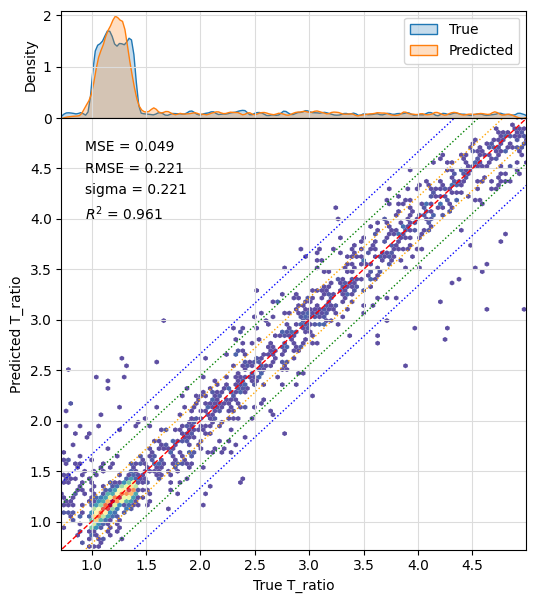

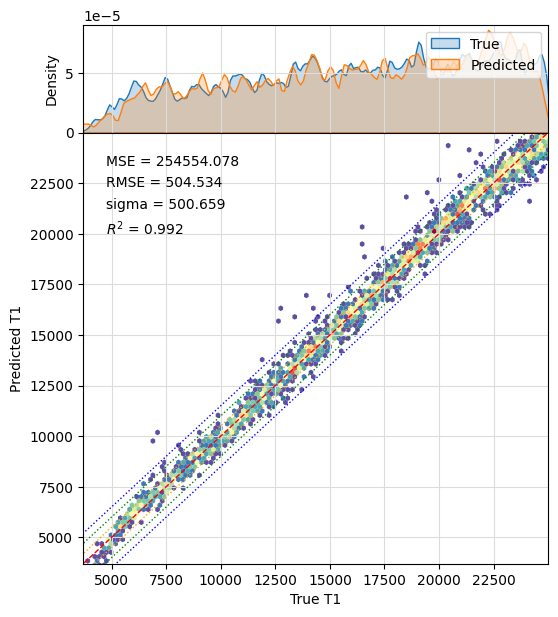

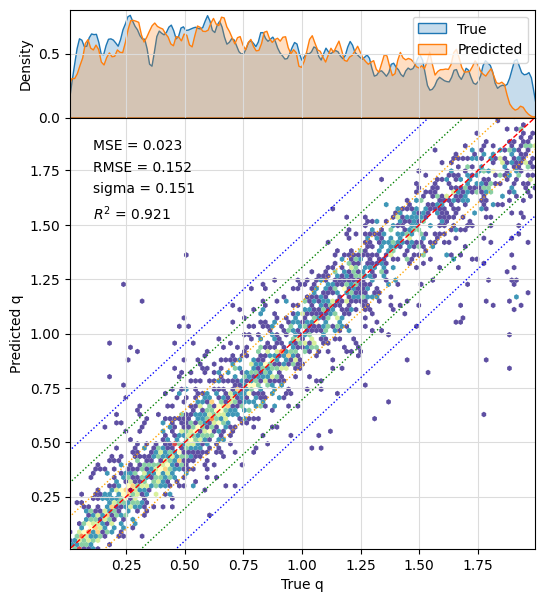

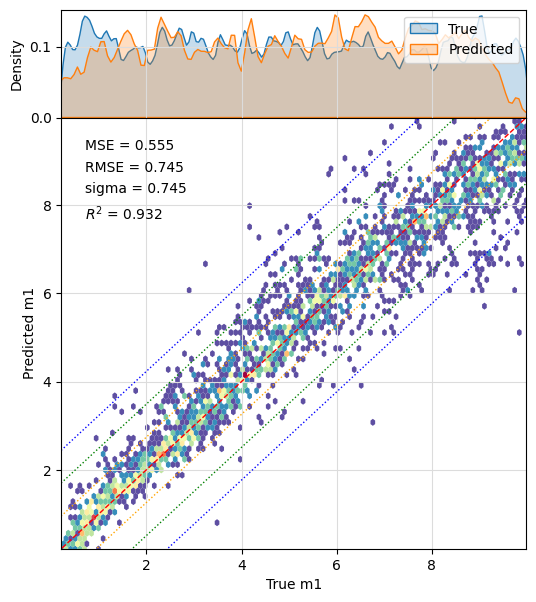

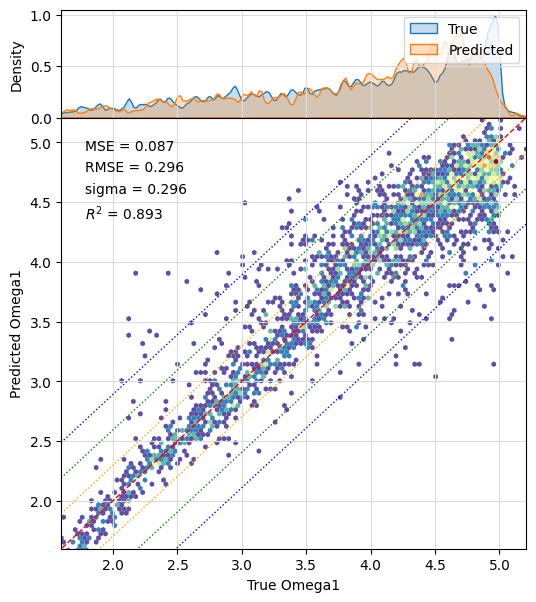

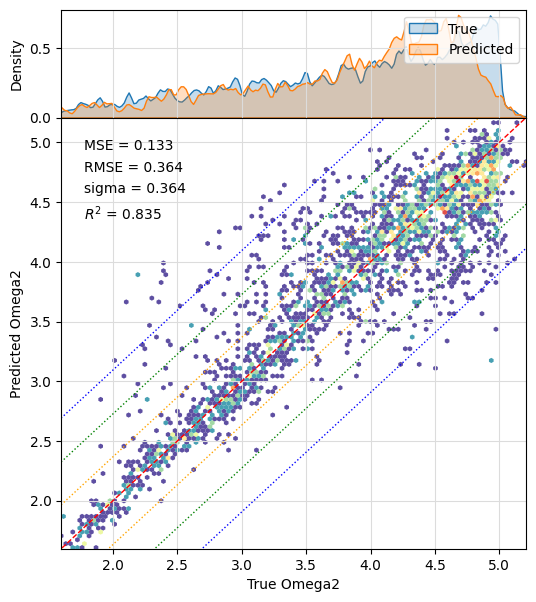

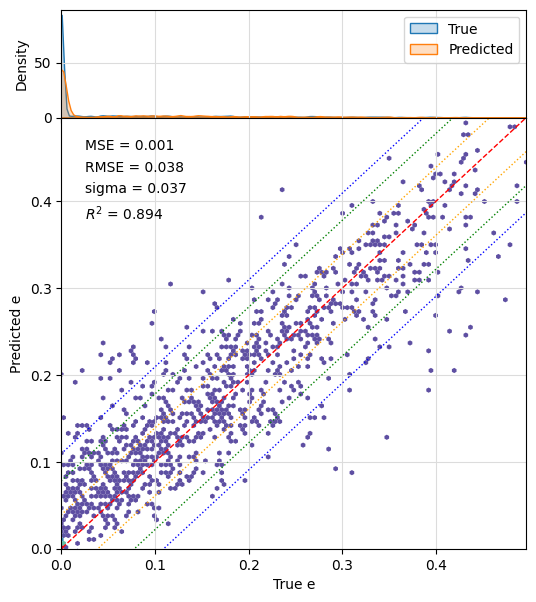

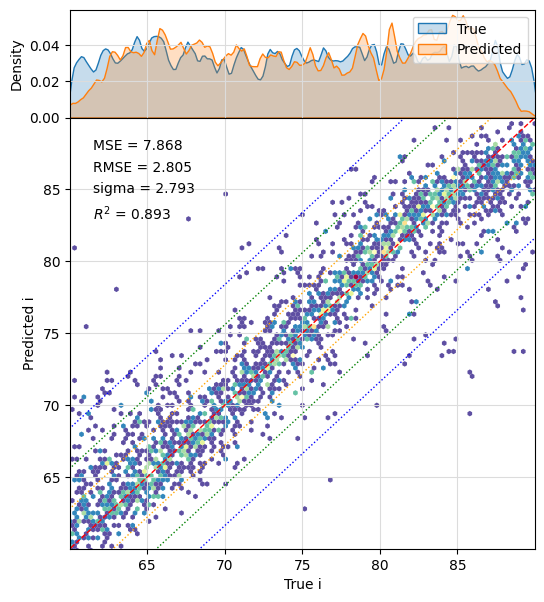

In [22]:
for i,name in enumerate(param_names):

    fig, (ax_kde, axs) = plt.subplots(2, 1, sharex=True, figsize=(6, 7),gridspec_kw={"height_ratios": [1, 4], "hspace": 0.0},)
    up_lim = max(true_phys[:,i])
    low_lim = min(true_phys[:,i])
    axs.hexbin(true_phys[:,i], pred_phys[:,i],cmap="Spectral_r", linewidths=0.0, mincnt=1)
    axs.plot([-100000,100000],[-100000,100000],"--",linewidth=1,c="red") # the ideal line on which pred = true
    axs.set_xlabel(f'True {name}')
    axs.set_ylabel(f'Predicted {name}')
    axs.set_xlim(left=low_lim,right=up_lim)
    axs.set_ylim(bottom=low_lim,top=up_lim)
    axs.grid(color='gainsboro')
    residuals = true_phys[:,i] - pred_phys[:,i] # residual: vertical distance from point to the ideal line (red dashed line)
    sigma = residuals.std()
    r2score = r2_score(true_phys[:,i],pred_phys[:,i])

    
    for j,c in enumerate(["orange","green","blue"],1):
        # plots dashed lines representing boundaries for data points within 1, 2 or 3 sigmas from the perfect
        axs.plot([-100000,100000],[-100000+sigma*j,100000+sigma*j],":",linewidth=1,c=c)
        axs.plot([-100000,100000],[-100000-sigma*j,100000-sigma*j],":",linewidth=1,c=c)

    sns.kdeplot(true_phys[:,i],ax=ax_kde, label='True',fill=True,bw_adjust=0.1)
    sns.kdeplot(pred_phys[:,i],ax=ax_kde, label="Predicted",fill=True,bw_adjust=0.1)
    ax_kde.grid(color='gainsboro')
    ax_kde.legend()
       

    axs.text(0.05,0.95, f'MSE = {phys_MSE[i]:.3f}', ha='left', va='top',transform=axs.transAxes) # average of the square residual. squared => large errors dominate
    axs.text(0.05,0.90, f'RMSE = {phys_RMSE[i]:.3f}',ha='left',va='top',transform=axs.transAxes) # root of mse. the typical distance of point to ideal line, back in its own units.
    axs.text(0.05,0.85, f'sigma = {sigma:.3f}',ha='left',va='top',transform=axs.transAxes) # standard deviation of the residuals. measures how spread out the errors are around their average
    axs.text(0.05,0.80, f'$R^2$ = {r2score:.3f}',ha='left',va='top',transform=axs.transAxes) # the fraction of variance in the true values that is explained by the model
# if rmse ~= sigma, then the data is normally distributed around the ideal line.



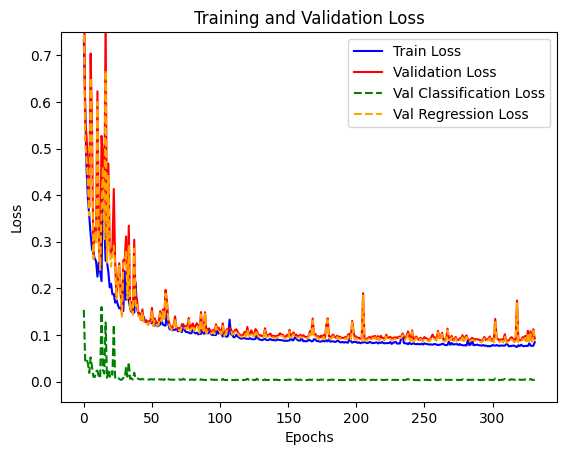

In [23]:
# Plot training/validation loss
plt.figure()
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="red")
plt.plot(val_C_losses, label='Val Classification Loss', color='green',linestyle='dashed')
plt.plot(val_R_losses, label='Val Regression Loss', color='orange',linestyle='dashed')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.ylim(top=0.75)
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

(12644, 100)


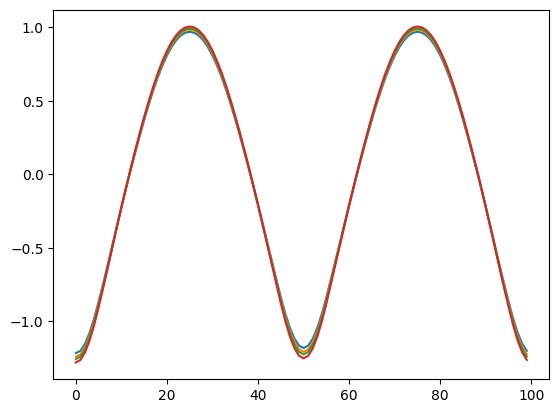

In [32]:
print(fluxes_normed['Generic.Bessell.B'].shape)


for band in passbands:
    plt.plot(fluxes_normed[band][6])